# 01 · Framing the churn problem

<sub>Telco churn analysis &nbsp;|&nbsp; **01 Framing** · 02 Cleaning & EDA · 03 Hypothesis tests · 04 Modelling · 05 A/B test & ROI</sub>

**Goal:** define *churn* and *cost of churn* precisely, before exploring the data.

> **Key findings**
>
> - 26.5 % of customers churned this quarter, taking **30.5 % of monthly revenue** with them.
> - Expected lifetime revenue lost: **≈ $1.37 M**.
> - Month-to-month customers are 89 % of churners but ~half of the lost lifetime value (short lifetimes).

## 1 · The business question

1. **Who churns, and why?** Which attributes are associated with churn, and how strongly.
2. **What does it cost?** Recurring revenue lost with those customers.
3. **What should we do?** Would a targeted retention offer pay for itself, and how do we prove it?

## 2 · Definitions

| | Definition |
|---|---|
| **Unit** | One customer account (7,043, all in California) |
| **Window** | One quarter |
| **Churn = 1** | `Churn Value == 1`: the customer left during the quarter |
| **Excluded** | `Churn Score` (IBM's own model output, leakage) · `Churn Reason` (only known after churn) · `Churn Label` (duplicates the target) · `CLTV` (opaque, used only for sizing) |

## 3 · Cost of churn

$$\text{cost per churner} = \underbrace{\text{monthly charges}}_{\text{lost revenue}} \times \underbrace{1/h}_{\text{expected remaining months}}, \qquad h = 1-(1-q)^{1/3}$$

where *q* is the segment's quarterly churn rate (segment = contract type) and *h* the implied monthly hazard. The expected remaining lifetime is capped at 72 months, the longest tenure observed.

> **Assumptions:** constant hazard within a segment · revenue, not margin · no discounting. The snapshot data supports **associations, not causation**, which is why notebook 05 designs an experiment.

## 4 · Sizing the problem

In [1]:
import sys, warnings; from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from churn import config as C, style, charts
style.setup()

In [2]:
from churn.data_cleaning import build_clean
from churn.ab_testing import cost_of_churn

df, _ = build_clean()
seg, _ = cost_of_churn(df)
lost_mrr = df.loc[df.churn == 1, "monthly_charges"].sum()

style.card({"Customers": f"{len(df):,}",
          "Churned this quarter": f"{df.churn.sum():,} ({df.churn.mean():.1%})",
          "Monthly revenue lost": f"${lost_mrr:,.0f} ({lost_mrr / df.monthly_charges.sum():.1%} of MRR)",
          "Lifetime revenue lost": f"${seg.revenue_lost.sum():,.0f}"}, caption="This quarter at a glance")

Customers,"7,043"
Churned this quarter,"1,869 (26.5%)"
Monthly revenue lost,"$139,131 (30.5% of MRR)"
Lifetime revenue lost,"$1,374,378"


In [3]:
style.table(seg[["quarterly_churn", "exp_remaining_months", "churners", "revenue_lost"]],
          fmt={"quarterly_churn": "{:.1%}", "exp_remaining_months": "{:.1f}", "churners": "{:,}",
               "revenue_lost": "${:,.0f}"},
          caption="Cost of churn by contract type", highlight=["Month-to-month"])

,quarterly_churn,exp_remaining_months,churners,revenue_lost
contract,,,,
Month-to-month,42.7%,5.9,"1,655","$713,129"
One year,11.3%,25.6,166,"$361,346"
Two year,2.8%,72.0,48,"$299,902"


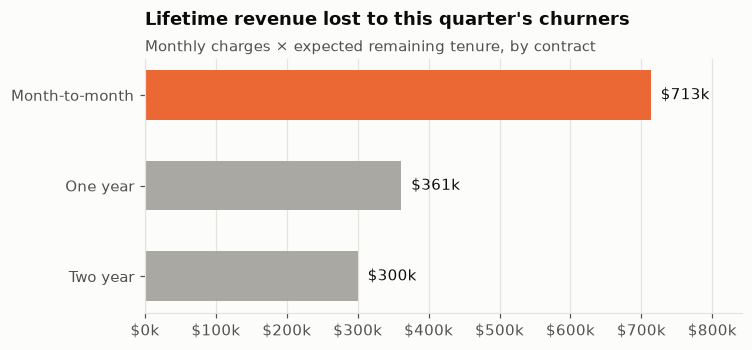

In [4]:
charts.revenue_lost(seg);

> **Takeaway:** month-to-month customers churn the most, but their short expected lifetime (~6 months) means each one is worth less than a churning contract customer. They are still the best target for a retention *offer*: numerous, reachable, and where small behaviour changes move the most customers.